# Experiment 4: Label-quality probe for lesion masks

In [1]:
# Imports and config
!pip install -q pydicom tifffile pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg opencv-python scikit-learn scipy tqdm openpyxl requests

import os, re, json, random, warnings, math, time, gc, zipfile, hashlib, requests
import numpy as np
import pandas as pd
import cv2
import pydicom, tifffile
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import ndimage
from scipy.ndimage import distance_transform_edt
from scipy.stats import rankdata
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

CBIS_PROJECT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom"     # our DICOM project (reference run); set to None to skip
DMID_ROOT    = "/content/DMID"                                             # DMID is downloaded here (Colab disk, about 5 GB, lost when the runtime resets)
BCDR_ROOT    = None                                                        # BCDR was not accessible: skipped. Set a folder path here to enable it later.
DOWNLOAD_DMID = True                                                       # False if DMID_ROOT already holds the extracted files
OUT_DIR      = "/content/drive/MyDrive/label_probe"; os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42; random.seed(SEED); np.random.seed(SEED)
CAPS = {'comparable (cap 256)': 256, 'fine (cap 1024)': 1024}      # longest side of the crop; 'comparable' matches the CBIS-DDSM pipeline
MARGIN_FACTOR, MARGIN_MIN = 0.7, 40                                # crop margin rule of Notebook 1
DMAX, WIN = 20, 15                                                 # profile range and gradient-peak search window (pixels)
CHANCE_PEAK = (2 * 3 + 1) / (2 * WIN + 1)                          # chance of a peak within +-3 px
MAX_AREA_FRAC, MIN_LESION_PX = 0.15, 100                           # a mask covering more than 15% of the image is not a lesion mask
SHIFT_PX, N_BOOT, MAX_AUC_PX = 8, 2000, 4000
IMG_EXT = ('.dcm', '.dicom', '.tif', '.tiff', '.png', '.jpg', '.jpeg', '.bmp')
IN_BAND, OUT_BAND = (1, 6), (1, 10)                                # the pipeline's evaluation band: 6 px inside, 10 px outside
print("Config loaded.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Config loaded.


## Download DMID

In [2]:
!pip install imagecodecs 2>&1 | tail -5
import sys; print(sys.version)
import imagecodecs; print("imagecodecs", imagecodecs.__version__)
print("lzw:", imagecodecs.lzw_check, imagecodecs.lzw_decode)

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
imagecodecs 2026.10.10
lzw: <cyfunction lzw_check at 0x79dd44fd94e0> <cyfunction lzw_decode at 0x79dd44fd9590>


In [3]:
FIGSHARE_ARTICLE = 24522883
DMID_WANTED = ('roi mask', 'metadata', 'dicom image')

def figshare_files(article):
    r = requests.get(f"https://api.figshare.com/v2/articles/{article}", timeout=60); r.raise_for_status(); return r.json()['files']

def fetch(url, out, size, md5=None):
    FALLBACK = "If this download is blocked, download the same files in your browser, extract them into DMID_ROOT (or upload to Drive and point DMID_ROOT there) and set DOWNLOAD_DMID = False."
    with requests.get(url, stream=True, timeout=120, allow_redirects=True, headers={'User-Agent': 'Mozilla/5.0'}) as r:
        r.raise_for_status(); h = hashlib.md5()
        if getattr(r, 'status_code', 200) != 200: raise RuntimeError(f"figshare answered HTTP {r.status_code} for {os.path.basename(out)} (a bot check, not the file). " + FALLBACK)
        with open(out, 'wb') as fh, tqdm(total=size or None, unit='B', unit_scale=True, desc=os.path.basename(out)) as bar:
            for chunk in r.iter_content(chunk_size=8 << 20):
                if chunk: fh.write(chunk); h.update(chunk); bar.update(len(chunk))
    if size and os.path.getsize(out) != size: raise RuntimeError(f"{os.path.basename(out)}: got {os.path.getsize(out)} bytes, expected {size}. " + FALLBACK)
    if md5 and h.hexdigest() != md5: raise RuntimeError(f"checksum mismatch for {os.path.basename(out)}: got {h.hexdigest()}, expected {md5}. " + FALLBACK)

def download_dmid(dest):
    files = figshare_files(FIGSHARE_ARTICLE); os.makedirs(dest, exist_ok=True)
    print("Files in the figshare record:"); [print(f"   {f['name']:<45s} {f['size'] / 1e6:10.1f} MB") for f in files]
    got = 0
    for f in files:
        nm = f['name']
        if not any(w in nm.lower() for w in DMID_WANTED): continue
        stem = os.path.splitext(nm)[0]; target = os.path.join(dest, stem if nm.lower().endswith('.zip') else '')
        marker = os.path.join(dest, f".done_{re.sub(r'[^A-Za-z0-9]+', '_', nm)}")
        if os.path.exists(marker): print("already done:", nm); got += 1; continue
        out = os.path.join(dest, nm); fetch(f['download_url'], out, f['size'], f.get('computed_md5') or None)
        if nm.lower().endswith('.zip'):
            with zipfile.ZipFile(out) as z: z.extractall(target)
            os.remove(out)                                   # keep the disk free; the extracted files stay
        open(marker, 'w').write('ok'); got += 1; print("fetched:", nm)
    assert got >= 2, f"expected at least the masks and the images, fetched {got}. Check the file names printed above and edit DMID_WANTED."
    print("DMID ready in", dest)

if DOWNLOAD_DMID: download_dmid(DMID_ROOT)
else: print("DOWNLOAD_DMID is False: using the files already in", DMID_ROOT)

Files in the figshare record:
   ROI Masks.zip                                        6.5 MB
   Reports.zip                                          0.2 MB
   Metadata.xlsx                                        0.0 MB
   DICOM Images.zip                                  4946.0 MB
   Pixel-level annotation.zip                        2134.0 MB
   TIFF Images.zip                                   4639.2 MB
already done: ROI Masks.zip
already done: Metadata.xlsx
already done: DICOM Images.zip
DMID ready in /content/DMID


## Discover each dataset folder

In [4]:
def discover(root, name, max_csv=6):
    print("=" * 70); print(name, "->", root)
    if not root or not os.path.isdir(root): print("  folder not found: skipped"); return
    ext, per_dir, csvs, xlsx = {}, {}, [], []
    for dp, _, fs in os.walk(root):
        for f in fs:
            e = os.path.splitext(f)[1].lower() or '(none)'; ext[e] = ext.get(e, 0) + 1; per_dir[dp] = per_dir.get(dp, 0) + 1
            if e == '.csv': csvs.append(os.path.join(dp, f))
            if e in ('.xlsx', '.xls'): xlsx.append(os.path.join(dp, f))
    print("  files by extension:", dict(sorted(ext.items(), key=lambda kv: -kv[1])[:12]))
    for dp, n in sorted(per_dir.items(), key=lambda kv: -kv[1])[:10]: print(f"  {n:6d} files  {os.path.relpath(dp, root)}")
    for p in csvs[:max_csv]:
        try:
            d = pd.read_csv(p, nrows=3); print(f"  csv {os.path.relpath(p, root)}: columns {list(d.columns)[:25]}"); print(d.head(2).to_string(max_colwidth=40)[:600])
        except Exception as e: print("  csv", os.path.relpath(p, root), "unreadable:", e)
    for p in xlsx[:3]:
        try:
            d = pd.read_excel(p, nrows=4); print(f"  xlsx {os.path.relpath(p, root)}: columns {list(d.columns)[:30]}"); print(d.head(3).to_string(max_colwidth=30)[:900])
        except Exception as e: print("  xlsx", os.path.relpath(p, root), "unreadable:", e)
    sample = [os.path.relpath(os.path.join(dp, f), root) for dp, _, fs in os.walk(root) for f in fs[:2]][:12]; print("  sample paths:", sample)
for nm, rt in (("CBIS-DDSM project", CBIS_PROJECT), ("DMID", DMID_ROOT), ("BCDR", BCDR_ROOT)): discover(rt, nm)

CBIS-DDSM project -> /content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom
  files by extension: {'.csv': 47, '.json': 32, '.npz': 13, '.png': 11, '.pkl': 6, '.joblib': 5, '.npy': 3, '.txt': 3, '.pt': 3}
      34 files  results
      24 files  results/nb6
      17 files  results/nb7
      11 files  models
      11 files  figures
       8 files  results/nb7/models
       7 files  outputs
       4 files  preprocessed
       2 files  trimaps
       2 files  results/nb9
  csv preprocessed/preprocessing_metadata.csv: columns ['image_id', 'class', 'lesion_key', 'view', 'roi_h', 'roi_w', 'fg_fraction', 'mask_fraction']
             image_id class      lesion_key view  roi_h  roi_w  fg_fraction  mask_fraction
0   P_00001_LEFT_1_CC  SPIC  P_00001_LEFT_1   CC    131    134     0.050074       0.104364
1  P_00001_LEFT_1_MLO  SPIC  P_00001_LEFT_1  MLO     95     87     0.022747       0.022747
  csv results/layer5_selection_val.csv: columns ['variant', 'hybrid', 'val_dice', 'val_sens', 'val_hd95', '

## Probe functions

In [5]:
def pwin(a, lo=1, hi=99):
    a = a.astype(np.float32); l, h = np.percentile(a, [lo, hi])
    return np.clip((a - l) / (h - l), 0, 1).astype(np.float32) if h > l else np.zeros_like(a)

def window_of(m):
    ys, xs = np.nonzero(m); r0, r1, c0, c1 = ys.min(), ys.max(), xs.min(), xs.max()
    mg = max(int(round(MARGIN_FACTOR * max(r1 - r0 + 1, c1 - c0 + 1))), MARGIN_MIN); h, w = m.shape
    return max(0, r0 - mg), min(h, r1 + mg + 1), max(0, c0 - mg), min(w, c1 + mg + 1)

def crop_and_cap(img, m, cap, win=None):
    R0, R1, C0, C1 = win or window_of(m)
    ci, cm = img[R0:R1, C0:C1].astype(np.float32), m[R0:R1, C0:C1]
    ls = max(ci.shape)
    if ls > cap:
        s = cap / ls; sz = (max(int(round(ci.shape[1] * s)), 8), max(int(round(ci.shape[0] * s)), 8))
        ci = cv2.resize(ci, sz, interpolation=cv2.INTER_AREA); cm = cv2.resize(cm.astype(np.uint8), sz, interpolation=cv2.INTER_NEAREST) > 0
    return ci, cm.astype(bool)

def signed_dist(m): return (distance_transform_edt(m) - distance_transform_edt(~m)).astype(np.float32)

def auc_rank(pos, neg, rng):
    if len(pos) < 20 or len(neg) < 20: return np.nan
    if len(pos) > MAX_AUC_PX: pos = rng.choice(pos, MAX_AUC_PX, replace=False)
    if len(neg) > MAX_AUC_PX: neg = rng.choice(neg, MAX_AUC_PX, replace=False)
    r = rankdata(np.concatenate([pos, neg])); return float((r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))

BINS = np.arange(-DMAX, DMAX + 1)
def probe_one(crop, mask, rng):
    roi = pwin(crop); z = ((roi - roi.mean()) / (roi.std() + 1e-6)).astype(np.float32); sd = signed_dist(mask)
    g = cv2.GaussianBlur(roi, (0, 0), 1.0); gm = np.sqrt(cv2.Sobel(g, cv2.CV_32F, 1, 0) ** 2 + cv2.Sobel(g, cv2.CV_32F, 0, 1) ** 2); gm = gm / (gm.mean() + 1e-6)
    si = np.clip(np.round(sd).astype(int), -DMAX, DMAX) + DMAX
    cnt = np.bincount(si.ravel(), minlength=len(BINS)).astype(float)
    pz = np.bincount(si.ravel(), weights=z.ravel(), minlength=len(BINS)) / np.maximum(cnt, 1)
    pg = np.bincount(si.ravel(), weights=gm.ravel(), minlength=len(BINS)) / np.maximum(cnt, 1)
    ok = cnt >= 5; pz[~ok] = np.nan; pg[~ok] = np.nan
    inn, out = (BINS >= 1) & (BINS <= 5), (BINS <= -1) & (BINS >= -5); sel = np.abs(BINS) <= WIN
    step = float(np.nanmean(pz[inn]) - np.nanmean(pz[out])) if np.isfinite(pz[inn]).any() and np.isfinite(pz[out]).any() else np.nan
    far = np.abs(BINS) >= 10
    ratio = float(np.nanmean(pg[np.abs(BINS) <= 1]) / np.nanmean(pg[far])) if np.isfinite(pg[far]).any() and np.isfinite(pg[np.abs(BINS) <= 1]).any() else np.nan
    peak = int(BINS[sel][np.nanargmax(pg[sel])]) if np.isfinite(pg[sel]).any() else np.nan
    sm = cv2.GaussianBlur(z, (0, 0), 2.0); ctx = cv2.blur(z, (5, 5)) - cv2.blur(z, (31, 31))
    inner = (sd >= IN_BAND[0]) & (sd <= IN_BAND[1]); outer = (sd <= -OUT_BAND[0]) & (sd >= -OUT_BAND[1])
    return ({'step': step, 'abs_step': abs(step) if np.isfinite(step) else np.nan, 'grad_ratio': ratio, 'peak': peak,
             'peak_in3': float(abs(peak) <= 3) if peak == peak else np.nan, 'auc_int': auc_rank(sm[inner], sm[outer], rng), 'auc_ctx': auc_rank(ctx[inner], ctx[outer], rng),
             'crop_side': int(max(crop.shape)), 'area_px': int(mask.sum())}, pz, pg)

def shift_mask(m, rng, px=SHIFT_PX):
    a = rng.uniform(0, 2 * np.pi); M = np.float32([[1, 0, px * np.cos(a)], [0, 1, px * np.sin(a)]])
    return cv2.warpAffine(m.astype(np.uint8), M, (m.shape[1], m.shape[0]), flags=cv2.INTER_NEAREST, borderValue=0) > 0

def lesion_components(mask):
    lab, n = ndimage.label(mask); comps, dropped = [], 0
    for k in range(1, n + 1):
        c = lab == k; a = int(c.sum())
        if a < MIN_LESION_PX or a > MAX_AREA_FRAC * mask.size: dropped += 1; continue
        comps.append(c)
    return comps, dropped
print("Probe functions ready.")

Probe functions ready.


## Loaders

In [6]:
MASK_RE = re.compile(r"\b(mask|masks|seg|segmented|segmentation|annot\w*|roi|label\w*|gt|groundtruth|ground truth)\b")
def is_mask_path(p, root):
    rel = os.path.relpath(p, root).lower().replace('_', ' ').replace('-', ' ').replace('.', ' '); return bool(MASK_RE.search(rel))
def stem_key(p):
    s = os.path.splitext(os.path.basename(p))[0].lower().replace('_', ' ').replace('-', ' '); s = MASK_RE.sub('', s); return re.sub(r"[^a-z0-9]+", '', s)
def is_image_file(f):
    e = os.path.splitext(f)[1].lower(); return e in IMG_EXT or (e == '' and os.path.getsize(f) > 100000 and pydicom.misc.is_dicom(f))

def read_any(path):
    if path.lower().endswith(('.dcm', '.dicom')) or '.' not in os.path.basename(path):
        ds = pydicom.dcmread(path); a = ds.pixel_array.astype(np.float32)
        if a.ndim == 3: a = a[..., 0] if a.shape[-1] in (3, 4) else a[0]
        if str(getattr(ds, 'PhotometricInterpretation', '')).upper() == 'MONOCHROME1': a = a.max() - a     # bright tissue = high values
        return a
    a = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if a is None: a = tifffile.imread(path)
    a = np.asarray(a)
    if a.ndim == 3: a = a[..., :3].astype(np.float32).mean(axis=2)
    return a.astype(np.float32)

def read_mask(path, shape):
    a = read_any(path); a = a > (0.5 * a.max()) if a.max() > 0 else np.zeros(a.shape, bool)
    if a.shape != tuple(shape): a = cv2.resize(a.astype(np.uint8), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    return a

def entries_cbis():
    cfg = json.load(open(os.path.join(CBIS_PROJECT, "config.json")))
    raw = np.load(os.path.join(cfg["PREPROCESSED_DIR"], "raw_crops.npz")); gt = np.load(os.path.join(cfg["PREPROCESSED_DIR"], "gt_masks.npz"))
    df = pd.read_csv(os.path.join(cfg["RESULTS_DIR"], "final_df_loaded.csv")); pat = dict(zip(df['image_id'], df['patient_id']))
    ids = sorted(set(raw.files) & set(gt.files))
    return [{'id': i, 'patient': pat.get(i, i), 'precropped': True, 'image': (lambda i=i: raw[i].astype(np.float32)), 'masks': (lambda shape, i=i: [gt[i] > 127])} for i in ids], {'note': 'precropped'}

def entries_dmid(root):
    files = [os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs if is_image_file(os.path.join(dp, f))]
    masks = [f for f in files if is_mask_path(f, root)]; images = [f for f in files if not is_mask_path(f, root)]
    by_key = {}
    for f in images: by_key.setdefault(stem_key(f), []).append(f)
    pairs, unmatched = [], 0
    for m in masks:
        k = stem_key(m); cands = by_key.get(k) or [v for kk, vs in by_key.items() if kk and (k.startswith(kk) or kk.startswith(k)) for v in vs]
        if len(cands) >= 1: pairs.append((cands[0], m))
        else: unmatched += 1
    info = {'images_found': len(images), 'mask_like_files': len(masks), 'pairs': len(pairs), 'masks_without_image': unmatched}
    if not pairs:
        print("  no image/mask pairs found. Sample image paths:", [os.path.relpath(p, root) for p in images[:6]]); print("  Sample mask-like paths:", [os.path.relpath(p, root) for p in masks[:6]])
        return [], info
    groups = {}
    for im, m in pairs: groups.setdefault(im, []).append(m)
    ents = []
    for im, ms in groups.items():
        iid = os.path.splitext(os.path.basename(im))[0]
        ents.append({'id': iid, 'patient': iid, 'precropped': False, 'image': (lambda im=im: read_any(im)), 'masks': (lambda shape, ms=ms: [read_mask(m, shape) for m in ms])})
    return ents, info

def entries_bcdr(root):
    imgs = {}
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(('.tif', '.tiff', '.png', '.jpg', '.jpeg', '.dcm')):
                imgs.setdefault(f.lower(), os.path.join(dp, f)); imgs.setdefault(os.path.splitext(f)[0].lower(), os.path.join(dp, f))
    ents, used, info = [], [], {'images_found': len(imgs) // 2, 'csv_with_polygons': 0, 'polygon_rows': 0, 'rows_without_image': 0}
    for dp, _, fs in os.walk(root):
        for f in fs:
            if not f.lower().endswith('.csv'): continue
            try: d = pd.read_csv(os.path.join(dp, f), sep=None, engine='python')
            except Exception: continue
            low = {c.lower(): c for c in d.columns}
            xc = [low[c] for c in low if 'x_points' in c or c.endswith('_x') or c == 'x_points']; yc = [low[c] for c in low if 'y_points' in c or c.endswith('_y') or c == 'y_points']
            fc = [low[c] for c in low if c in ('image_filename', 'filename', 'image_file', 'image', 'img_filename', 'file_name')]
            if not xc or not yc or not fc: continue
            info['csv_with_polygons'] += 1; pc = [low[c] for c in low if c in ('patient_id', 'patient')]
            for ri, r in d.iterrows():
                info['polygon_rows'] += 1; fn = str(r[fc[0]]).strip().lower(); p = imgs.get(fn) or imgs.get(os.path.splitext(fn)[0]) or imgs.get(os.path.basename(fn))
                if p is None: info['rows_without_image'] += 1; continue
                xs = [float(v) for v in re.findall(r"-?\d+\.?\d*", str(r[xc[0]]))]; ys = [float(v) for v in re.findall(r"-?\d+\.?\d*", str(r[yc[0]]))]
                if len(xs) < 3 or len(xs) != len(ys): continue
                iid = f"{os.path.splitext(os.path.basename(p))[0]}_r{ri}"; pat = str(r[pc[0]]) if pc else iid
                ents.append({'id': iid, 'patient': pat, 'precropped': False, 'image': (lambda p=p: read_any(p)),
                             'masks': (lambda shape, xs=xs, ys=ys: [poly_mask(shape, xs, ys)])})
    if not ents: print("  no polygon rows matched an image. Check the csv columns printed by the Discover cell.")
    return ents, info

def poly_mask(shape, xs, ys):
    m = np.zeros(shape, np.uint8); cv2.fillPoly(m, [np.round(np.stack([xs, ys], axis=1)).astype(np.int32)], 1); return m > 0
print("Loaders ready.")

Loaders ready.


## Run the probe on every dataset that is present

In [7]:
!pip install -q imagecodecs
import importlib, imagecodecs, tifffile
print("imagecodecs", imagecodecs.__version__, "| LZW available:", imagecodecs.LZW.available if hasattr(imagecodecs, "LZW") else "ok")

imagecodecs 2026.10.10 | LZW available: True


In [8]:
def run_dataset(name, ents, caps):
    rng = np.random.default_rng(SEED); rows, profs, montage, dropped = [], [], [], 0
    for e in tqdm(ents, desc=name, leave=False):
        try: img = e['image'](); ms = e['masks'](img.shape)
        except Exception as ex: print(f"  skipped {e['id']}: {ex}"); dropped += 1; continue
        for mk in ms:
            if e['precropped']: comps = [mk.astype(bool)]
            else:
                comps, nd = lesion_components(mk); dropped += nd
            for k, comp in enumerate(comps):
                for cname, cap in caps.items():
                    if e['precropped']:
                        if cname != 'comparable (cap 256)': continue
                        crop, m = img, comp
                    else:
                        win = window_of(comp); R0, R1, C0, C1 = win
                        if (mk[R0:R1, C0:C1] & ~comp[R0:R1, C0:C1]).any(): dropped += 1; continue      # a second lesion inside the crop would count as "outside"
                        crop, m = crop_and_cap(img, comp, cap, win)
                        if m.sum() < 30 or m.sum() == m.size: dropped += 1; continue
                    lid = f"{e['id']}#{k}"
                    for kind, mm in (('real', m), ('shifted control', shift_mask(m, rng))):
                        if mm.sum() < 20 or mm.sum() == mm.size: continue
                        sc, pz, pg = probe_one(crop, mm, rng); sc.update(dataset=name, setting=cname, kind=kind, id=lid, patient=e['patient']); rows.append(sc); profs.append((name, cname, kind, pz, pg))
                    if cname == 'comparable (cap 256)' and len(montage) < 8: montage.append((lid, crop, m))
    return pd.DataFrame(rows), profs, montage, dropped

DATASETS = []
if CBIS_PROJECT and os.path.isdir(CBIS_PROJECT):
    try: DATASETS.append(("CBIS-DDSM (reference)",) + entries_cbis())
    except Exception as ex: print("CBIS-DDSM reference skipped:", ex)
if DMID_ROOT and os.path.isdir(DMID_ROOT): DATASETS.append(("DMID",) + entries_dmid(DMID_ROOT))
if BCDR_ROOT and os.path.isdir(BCDR_ROOT): DATASETS.append(("BCDR",) + entries_bcdr(BCDR_ROOT))
print("Datasets:", [(n, len(e), info) for n, e, info in DATASETS])

ALL_ROWS, ALL_PROFS, MONTAGES, DROPS = [], [], {}, {}
for name, ents, info in DATASETS:
    if not ents: print(f"{name}: no usable entries, skipped"); continue
    df, pr, mo, dr = run_dataset(name, ents, CAPS); ALL_ROWS.append(df); ALL_PROFS += pr; MONTAGES[name] = mo; DROPS[name] = dr
    print(f"{name}: {df[(df['kind'] == 'real') & (df['setting'] == 'comparable (cap 256)')]['id'].nunique()} lesions analysed, {dr} dropped (multi-lesion crops, tiny or oversized masks, unreadable files)")
PER = pd.concat(ALL_ROWS, ignore_index=True) if ALL_ROWS else pd.DataFrame()
PER.to_csv(os.path.join(OUT_DIR, "label_probe_per_lesion.csv"), index=False)

Datasets: [('CBIS-DDSM (reference)', 1067, {'note': 'precropped'}), ('DMID', 269, {'images_found': 510, 'mask_like_files': 269, 'pairs': 269, 'masks_without_image': 0})]


CBIS-DDSM (reference): 1067 lesions analysed, 0 dropped (multi-lesion crops, tiny or oversized masks, unreadable files)


DMID: 275 lesions analysed, 313 dropped (multi-lesion crops, tiny or oversized masks, unreadable files)


## Summary table

In [9]:
def boot_mean(vals, pats, n=N_BOOT, seed=SEED):
    d = pd.DataFrame({'v': vals, 'p': pats}).dropna();
    if len(d) < 3: return np.nan, np.nan, np.nan
    g = d.groupby('p')['v'].agg(['sum', 'count']); s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    ix = np.random.default_rng(seed).integers(0, len(g), size=(n, len(g))); b = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(d['v'].mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

fmt = lambda t: "" if not np.isfinite(t[0]) else f"{t[0]:.3f} [{t[1]:.3f}, {t[2]:.3f}]"
rows = []
for (ds, st, kd), g in PER.groupby(['dataset', 'setting', 'kind'], sort=False):
    n_pat = g['patient'].nunique()
    rows.append({'dataset': ds, 'setting': st, 'kind': kd, 'lesions': len(g), 'bootstrap units': ('patients' if n_pat < len(g) else 'images'), 'median crop side': int(g['crop_side'].median()),
                 'intensity step': fmt(boot_mean(g['step'], g['patient'])), 'share positive step': f"{(g['step'] > 0).mean():.2f}",
                 'peak within +-3 px': fmt(boot_mean(g['peak_in3'], g['patient'])), 'chance': f"{CHANCE_PEAK:.3f}", 'median gradient ratio': f"{g['grad_ratio'].median():.2f}",
                 'band AUC intensity': fmt(boot_mean(g['auc_int'], g['patient'])), 'band AUC local contrast': fmt(boot_mean(g['auc_ctx'], g['patient']))})
SUM = pd.DataFrame(rows); SUM.to_csv(os.path.join(OUT_DIR, "label_probe_summary.csv"), index=False)
pd.set_option('display.width', 300); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 40)
print("LABEL-QUALITY PROBE (95% bootstrap CI in brackets; bootstrap unit shown)"); print(SUM.to_string(index=False)); print("")
print(f"Chance for the gradient-peak measure: {CHANCE_PEAK:.3f}. Band AUC chance: 0.5. Compare each real row with its shifted control (masks moved {SHIFT_PX} px): if they are alike, the outline is no better aligned with the image than a displaced copy.")
if (SUM['bootstrap units'] == 'images').any(): print("NOTE: for datasets marked 'images' no patient ids were found, so the intervals treat lesions as independent and are optimistic.")

LABEL-QUALITY PROBE (95% bootstrap CI in brackets; bootstrap unit shown)
              dataset              setting            kind  lesions bootstrap units  median crop side       intensity step share positive step   peak within +-3 px chance median gradient ratio   band AUC intensity band AUC local contrast
CBIS-DDSM (reference) comparable (cap 256)            real     1067        patients               111 0.014 [0.003, 0.024]                0.56 0.229 [0.203, 0.256]  0.226                  0.99 0.517 [0.509, 0.524]    0.502 [0.494, 0.511]
CBIS-DDSM (reference) comparable (cap 256) shifted control     1064        patients               111 0.012 [0.002, 0.022]                0.54 0.239 [0.211, 0.264]  0.226                  0.99 0.516 [0.509, 0.523]    0.501 [0.492, 0.510]
                 DMID comparable (cap 256)            real      275        patients               256 0.196 [0.163, 0.233]                0.75 0.309 [0.256, 0.366]  0.226                  1.09 0.601 [0.586, 0.617]

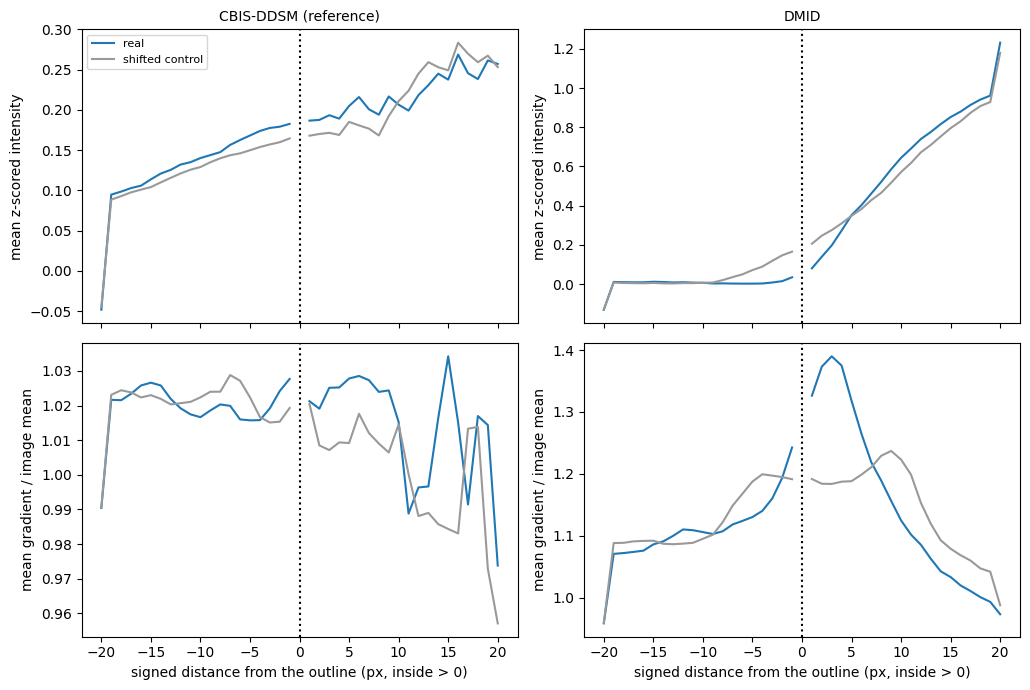

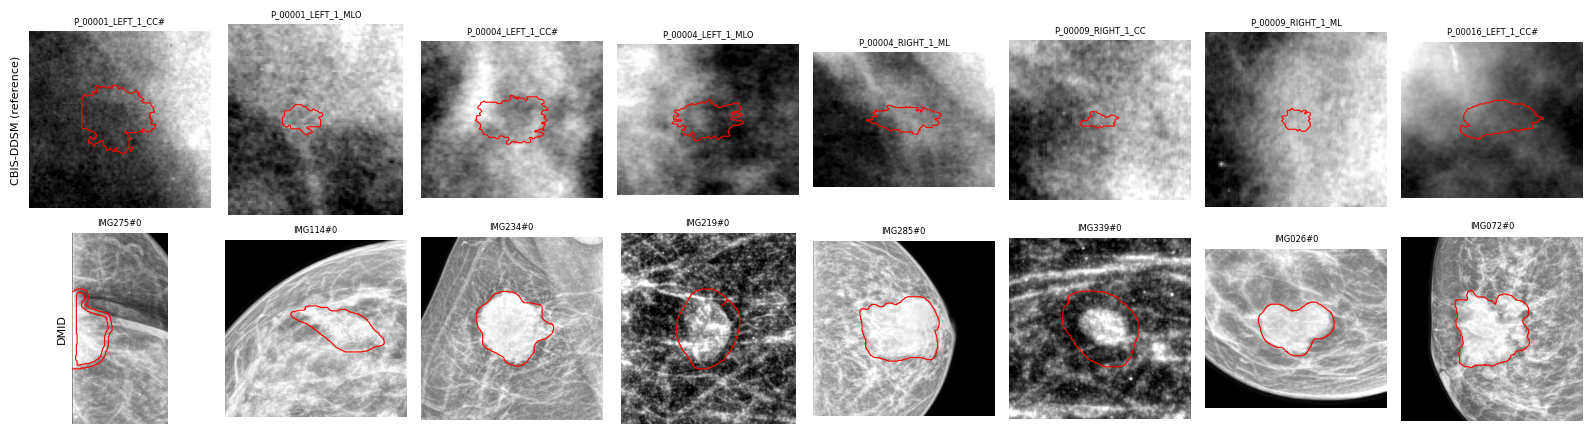

Look at the montage: the red outline should hug a visible edge if the labels are tight. Also check that the mass looks BRIGHT (if it looks dark, the file may be inverted and the signed step is flipped).


In [10]:
fig, axes = plt.subplots(2, max(len(DATASETS), 1), figsize=(5.2 * max(len(DATASETS), 1), 7), sharex=True, squeeze=False)
for k, (name, _, _) in enumerate(DATASETS):
    for kind, col in (('real', '#1f77b4'), ('shifted control', '#999999')):
        sel = [(pz, pg) for n, c, kd, pz, pg in ALL_PROFS if n == name and c == 'comparable (cap 256)' and kd == kind]
        if not sel: continue
        axes[0, k].plot(BINS, np.nanmean([a for a, _ in sel], axis=0), color=col, label=kind); axes[1, k].plot(BINS, np.nanmean([b for _, b in sel], axis=0), color=col, label=kind)
    for a in axes[:, k]: a.axvline(0, color='k', ls=':')
    axes[0, k].set_title(name, fontsize=10); axes[0, k].set_ylabel("mean z-scored intensity"); axes[1, k].set_ylabel("mean gradient / image mean"); axes[1, k].set_xlabel("signed distance from the outline (px, inside > 0)")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_label_probe_profiles.png"), dpi=150); plt.show()

names = [n for n in MONTAGES if MONTAGES[n]]
if names:
    fig, axes = plt.subplots(len(names), 8, figsize=(16, 2.2 * len(names)), squeeze=False)
    for r, n in enumerate(names):
        for c in range(8):
            ax = axes[r, c]; ax.axis('off')
            if c < len(MONTAGES[n]):
                lid, crop, m = MONTAGES[n][c]; ax.imshow(pwin(crop), cmap='gray'); ax.contour(m.astype(float), levels=[0.5], colors='r', linewidths=0.8); ax.set_title(lid[:18], fontsize=6)
        axes[r, 0].text(-0.05, 0.5, n, transform=axes[r, 0].transAxes, rotation=90, va='center', ha='right', fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_label_probe_montage.png"), dpi=150); plt.show()
    print("Look at the montage: the red outline should hug a visible edge if the labels are tight. Also check that the mass looks BRIGHT (if it looks dark, the file may be inverted and the signed step is flipped).")

In [11]:
# Save label probe profiles
names_  = np.array([p[0] for p in ALL_PROFS]); sets_ = np.array([p[1] for p in ALL_PROFS]); kinds_ = np.array([p[2] for p in ALL_PROFS])
pz_, pg_ = np.stack([p[3] for p in ALL_PROFS]), np.stack([p[4] for p in ALL_PROFS])
np.savez_compressed(os.path.join(OUT_DIR, "label_probe_profiles.npz"), bins=BINS, dataset=names_, setting=sets_, kind=kinds_, pz=pz_, pg=pg_)

In [12]:
def verify_nb8():
    real = PER[(PER['kind'] == 'real') & (PER['setting'] == 'comparable (cap 256)')]; ctl = PER[(PER['kind'] == 'shifted control') & (PER['setting'] == 'comparable (cap 256)')]
    checks = {
        "at least one dataset was analysed"                                : len(real) > 0,
        "the CBIS-DDSM reference run is present"                          : (real['dataset'] == 'CBIS-DDSM (reference)').any(),
        "every analysed dataset has a shifted control"                    : set(real['dataset']) <= set(ctl['dataset']),
        "metrics finite for real and shifted masks"                       : all(np.isfinite(g[['step', 'auc_int']]).all().all() or g[['step', 'auc_int']].notna().mean().min() > 0.8 for _, g in PER.groupby(['dataset', 'kind'])),
        "outputs saved"                                                    : all(os.path.exists(os.path.join(OUT_DIR, f)) for f in ("label_probe_summary.csv", "label_probe_per_lesion.csv", "fig_label_probe_profiles.png")),
    }
    print("=" * 60); print("NOTEBOOK 8 VERIFICATION"); print("=" * 60); ok = True
    for k, v in checks.items(): print(f"  {'OK  ' if bool(v) else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 60); print("Probe complete." if ok else "Review failures."); return ok
verify_nb8()

NOTEBOOK 8 VERIFICATION
  OK    at least one dataset was analysed
  OK    the CBIS-DDSM reference run is present
  OK    every analysed dataset has a shifted control
  OK    metrics finite for real and shifted masks
  OK    outputs saved
Probe complete.


True